# Learn a carrier, swap it and steer it

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AdaptiveMotorControlLab/psi/blob/main/notebooks/01-quickstart.ipynb)

Declare an option-position variable and reuse one fitted model for donor swaps and requested answers.

In [1]:
%pip install -q "psi[notebooks] @ git+https://github.com/AdaptiveMotorControlLab/psi"

Choose the model and budget in this cell. Set `SMOKE = True` for a small CPU run.

In [2]:
# Edit these settings directly. SMOKE gives a small CPU check.
SMOKE = False
MODEL_ID = "Qwen/Qwen2.5-0.5B"
EPOCHS = 8
BATCH_SIZE = 4
MAX_LENGTH = 64


In [3]:
%matplotlib inline

import logging
import tempfile
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

import psi

# These settings are derived from the configuration cell above.
DEVICE = "cpu"
if not SMOKE and torch.cuda.is_available():
    DEVICE = "cuda"
DTYPE = "float32" if DEVICE == "cpu" else "float16"
EPOCHS = 1 if SMOKE else EPOCHS
BATCH_SIZE = 2 if SMOKE else BATCH_SIZE
CACHE = tempfile.mkdtemp(prefix="psi-demo-")
START = time.perf_counter()

torch.set_num_threads(4)
logging.getLogger("lightning.pytorch").setLevel(logging.ERROR)
warnings.formatwarning = (
    lambda message, category, *args, **kwargs: f"{category.__name__}: {message}\n"
)

# Colours and axis treatment follow the paper's figures.
PSI_COLOUR = "#A03BB8"
SECONDARY = "#1E8158"
REFERENCE = "#7593C6"
NO_EDIT = "#BFBFBC"
INK = "#0b0b0b"
INK_SOFT = "#4a4a47"

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 11,
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "axes.edgecolor": INK,
    "axes.labelcolor": INK,
    "axes.linewidth": 0.8,
    "xtick.color": INK_SOFT,
    "ytick.color": INK_SOFT,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "legend.frameon": False,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "figure.dpi": 120,
    "savefig.dpi": 160,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

The preset retains each prompt's own option labels. `Slots("choices.label")` studies the selected position. A copy asks the base to choose its own option in the donor's preferred slot.

In [4]:
prompts, program = psi.presets.mcqa(limit=4 if SMOKE else 64)

model = psi.PSI(
    MODEL_ID,
    layer=15,
    rank=16,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    max_length=MAX_LENGTH,
    device=DEVICE,
    dtype=DTYPE,
    steering=True,
    cache_dir=CACHE,
    progress=False,
)

check = program.check(model, prompts)
print(check)

README.md:   0%|          | 0.00/2.70k [00:00<?, ?B/s]

train.jsonl:   0%|          | 0.00/303k [00:00<?, ?B/s]

validation.jsonl:   0%|          | 0.00/137k [00:00<?, ?B/s]

test.jsonl:   0%|          | 0.00/138k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/110 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/50 [00:00<?, ? examples/s]

... (6 outputs left out)

model.safetensors:   0%|          | 0.00/988M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

mean_answer_mass: 0.7863202095031738
lowest_answer_mass: 0.05626127868890762
argmax_counts: (133, 158, 170, 195)
gold_agreement: 0.8353658318519592
leading_space_mass: 0.7863202095031738
warnings: ()


Inspect answer mass and answer counts before fitting. `steering=True` trains the controller jointly with the carrier, so this fit supports both operations below. Gold labels are available for evaluation; the correctness filter is off.

In [5]:
model.fit(prompts, program)

report = model.score(prompts, split="test")
display(report.to_frame())

GPU available: True (cuda), used: True


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


You are using a CUDA device ('NVIDIA RTX A4000') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [2]


/opt/venv/lib/python3.12/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/opt/venv/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=19` in the `DataLoader` to improve performance.
/opt/venv/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=19` in the `DataLoader` to improve performance.


`Trainer.fit` stopped: `max_epochs=8` reached.


,interchange_agreement,no_edit_baseline,mean_answer_mass,prompts,pairs,steering_success,steering_no_edit,model_agreement,no_edit_model_agreement,decision_rule
0,0.946667,0.333333,0.798538,200,150,0.90375,0.25,0.806667,0.266667,declared-answer argmax


For this preset, interchange agreement uses gold pair targets. Model agreement uses the donor's frozen reading. The baselines use the same comparisons before editing. Requested-answer success asks for every declared slot. All these decisions use argmax over declared answers.

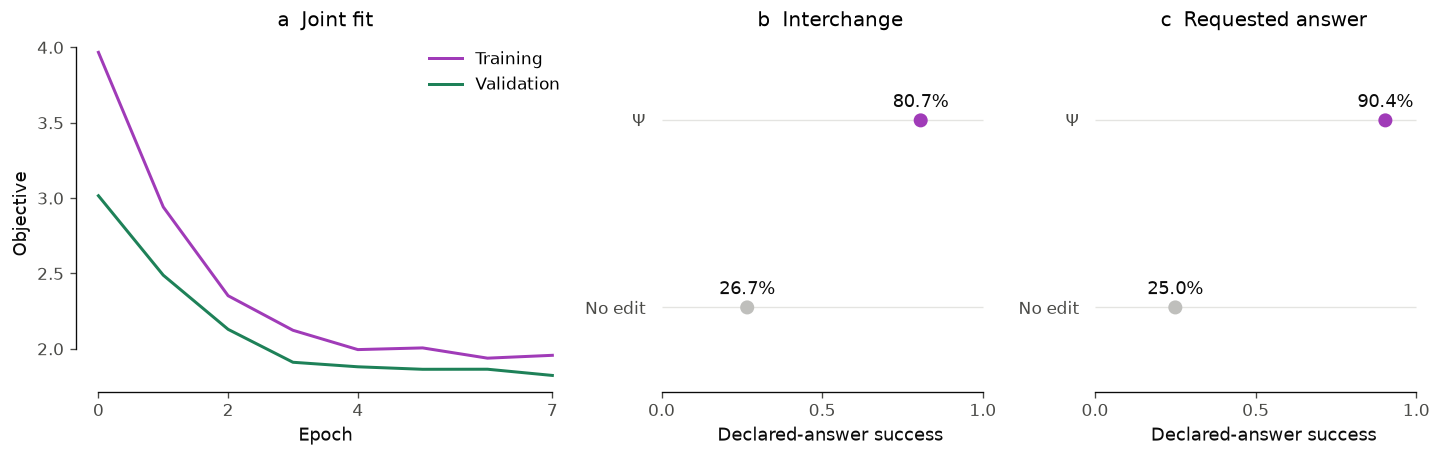

In [6]:
history = model.history
fig, axes = plt.subplots(
    1, 3,
    figsize=(12, 3.7),
    gridspec_kw={"width_ratios": [1.4, 1, 1]},
    layout="constrained",
)

curve = axes[0]
curve.plot(history.epoch, history["train/loss"], color=PSI_COLOUR, label="Training", linewidth=1.8)
curve.plot(history.epoch, history["val/loss"], color=SECONDARY, label="Validation", linewidth=1.8)
curve.set(xlabel="Epoch", ylabel="Objective", title="a  Joint fit")
curve.legend(loc="best")

# Spine endpoints coincide with the first and last displayed ticks.
epoch_ticks = np.unique(np.linspace(history.epoch.min(), history.epoch.max(), min(len(history), 4)).astype(int))
curve.set_xticks(epoch_ticks)
curve.spines[["top", "right"]].set_visible(False)
curve.spines["bottom"].set_bounds(epoch_ticks[0], epoch_ticks[-1])
loss_ticks = curve.get_yticks()
loss_ticks = loss_ticks[(loss_ticks >= curve.get_ylim()[0]) & (loss_ticks <= curve.get_ylim()[1])]
curve.set_yticks(loss_ticks)
curve.spines["left"].set_bounds(loss_ticks[0], loss_ticks[-1])

comparisons = [
    ("b  Interchange", report.no_edit_model_agreement, report.model_agreement),
    ("c  Requested answer", report.steering_no_edit, report.steering_success),
]

for axis, (title, baseline, learned) in zip(axes[1:], comparisons):
    axis.hlines([0, 1], 0, 1, color="#e4e4e1", linewidth=0.8)
    axis.scatter([baseline, learned], [0, 1], c=[NO_EDIT, PSI_COLOUR], s=55, zorder=3)
    axis.set(xlim=(-0.03, 1.08), ylim=(-0.45, 1.45), title=title, xlabel="Declared-answer success")
    axis.set_xticks([0, 0.5, 1])
    axis.set_yticks([0, 1], ["No edit", r"$\Psi$"])
    axis.spines[["top", "right", "left"]].set_visible(False)
    axis.spines["bottom"].set_bounds(0, 1)
    axis.tick_params(axis="y", length=0)

    for value, row in [(baseline, 0), (learned, 1)]:
        axis.annotate(f"{value:.1%}", (value, row), xytext=(0, 8), textcoords="offset points", ha="center", color=INK)

plt.show()

Inspect three swaps from the held-out pairs. Each table row reports the prompt, the donor's preferred slot, and the base's answer before and after the carrier swap.

In [7]:
examples = []
swap_readings = []

for pair in prompts.pairs["test"][:3]:
    base = prompts.splits["test"][pair["base_index"]]
    donor = prompts.splits["test"][pair["source_index"]]
    reading = model.swap(base=base, donor=donor)
    swap_readings.append(reading)

    examples.append({
        "base": base["prompt"],
        "donor": donor["prompt"],
        "before": reading.loc[reading.base_before.idxmax(), "base_answer"],
        "donor_slot": int(reading.donor_before.idxmax()),
        "after": reading.loc[reading.base_after.idxmax(), "base_answer"],
    })

display(pd.DataFrame(examples))

,base,donor,before,donor_slot,after
0,Question: Broccoli is green. What color is bro...,Question: Broccoli is green. What color is bro...,D,0,A
1,Question: Broccoli is green. What color is bro...,Question: Broccoli is green. What color is bro...,D,3,D
2,Question: Broccoli is green. What color is bro...,Question: Broccoli is green. What color is bro...,D,3,A


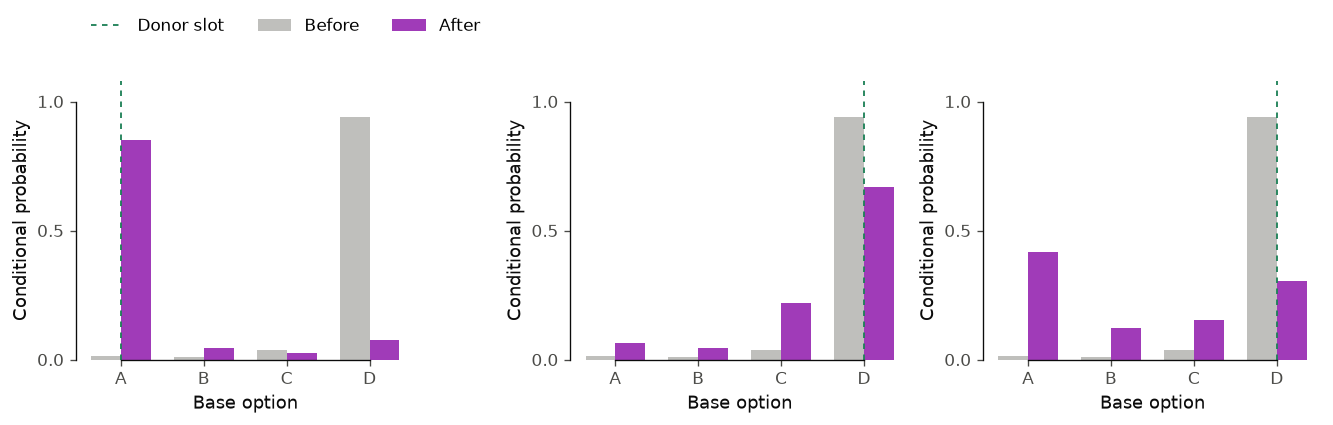

In [8]:
fig, axes = plt.subplots(1, len(swap_readings), figsize=(11, 3.4), layout="constrained")

for axis, reading, example in zip(np.atleast_1d(axes), swap_readings, examples):
    slots = np.arange(len(reading))
    axis.bar(slots - 0.18, reading.base_before, width=0.36, color=NO_EDIT, label="Before")
    axis.bar(slots + 0.18, reading.base_after, width=0.36, color=PSI_COLOUR, label="After")
    axis.axvline(example["donor_slot"], color=SECONDARY, linestyle=(0, (3, 3)), linewidth=1.1, label="Donor slot")
    axis.set_xticks(slots, reading.base_answer.str.strip())
    axis.set_yticks([0, 0.5, 1])
    axis.set(ylim=(0, 1.08), xlabel="Base option", ylabel="Conditional probability")
    axis.spines[["top", "right"]].set_visible(False)
    axis.spines["bottom"].set_bounds(slots[0], slots[-1])
    axis.spines["left"].set_bounds(0, 1)

axes[0].legend(loc="upper left", bbox_to_anchor=(0, 1.28), ncol=3)
plt.show()

Request an answer without a donor using the same fitted model. The controller was enabled before the fit. The request below names a slot in each prompt's own option list.

In [9]:
steered_examples = []

for index, prompt in enumerate(prompts.splits["test"][:3]):
    requested = index % len(prompt["choices"]["label"])
    response = model.steer(prompt, answer=requested)

    steered_examples.append({
        "prompt": prompt["prompt"],
        "requested": response.loc[requested, "answer"],
        "before": response.loc[response.before.idxmax(), "answer"],
        "after": response.loc[response.after.idxmax(), "answer"],
    })

display(pd.DataFrame(steered_examples))

,prompt,requested,before,after
0,Question: Broccoli is green. What color is bro...,A,D,A
1,Question: Broccoli is green. What color is bro...,B,A,B
2,Question: Broccoli is green. What color is bro...,W,I,I


This run uses its own model and budget. The paper's localization and control settings are described in [arXiv 2611.21307](https://arxiv.org/abs/2611.21307). Its control evaluation also measures unrestricted greedy generation.

This run record reports the model, hardware, elapsed time and the held-out scores measured above.

In [10]:
run_summary = {
    "model": MODEL_ID,
    "device": DEVICE,
    "gpu": torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU",
    "runtime_seconds": time.perf_counter() - START,
    "smoke": SMOKE,
    "card": {
        "metric": "Held-out declared-answer success",
        "rows": [
            {"label": "Donor swap", "edit": float(report.model_agreement), "baseline": float(report.no_edit_model_agreement)},
            {"label": "Requested answer", "edit": float(report.steering_success), "baseline": float(report.steering_no_edit)},
        ],
        "pairs": int(report.pairs),
    },
}
display({"application/json": run_summary}, raw=True)